# Student Pass Classification

This notebook uses `data/student_classification.csv`. Each row is one student. `Passed` is 0 (fail) or 1 (pass). The inputs are study hours, attendance, and assignment score.

The steps are:

1. Drop duplicate rows and rows with a missing value, before any charts.
2. Look at the cleaned table.
3. Train logistic regression and k-nearest neighbors. On this file, k-nearest neighbors makes fewer mistakes, and the confusion matrices show that.
4. Train a support vector machine, a decision tree, and a random forest on the same split.


In [ ]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrixsklearn.
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Keep the plots in the notebook, and use the same grid style as the other demos.
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
%matplotlib inline


## Load the data

`Student_ID` only identifies a row. The three numeric columns are the inputs. `Passed` is the class we want to predict.


In [2]:
# The notebook lives in Demo/, so the CSV is one folder up.
# The second path is a fallback if this cell is run from the project root.
path = Path("../data/student_classification.csv")
if not path.exists():
    path = Path("data/student_classification.csv")

students = pd.read_csv(path)

print("Rows and columns:", students.shape)
students.head()


Rows and columns: (500, 5)


,Student_ID,Study_Hours,Attendance,Assignment_Score,Passed
0,S001,7.9,90,69,0
1,S002,4.7,86,52,1
2,S003,8.7,76,50,0
3,S004,7.1,94,56,0
4,S005,1.4,52,74,0


## Remove missing values and duplicate rows

A copied row would be counted twice. A row with a blank cell cannot be used, because every model below needs a number in every column. Those rows are dropped here, so the charts in the next section are drawn from the cleaned table only.


In [3]:
print("Rows before cleaning:", len(students))
print("Missing values before cleaning:", int(students.isna().sum().sum()))
print("Duplicate rows before cleaning:", int(students.duplicated().sum()))

# Keep the first copy of a repeated row, and drop the rest.
students = students.drop_duplicates()

# Drop any row that still has a blank cell.
students = students.dropna().reset_index(drop=True)

# After dropna, make sure the class column is a plain 0 or 1.
students["Passed"] = students["Passed"].astype(int)

print()
print("Rows after cleaning:", len(students))
print("Missing values left:", int(students.isna().sum().sum()))
print("Duplicate rows left:", int(students.duplicated().sum()))


Rows before cleaning: 500
Missing values before cleaning: 0
Duplicate rows before cleaning: 0

Rows after cleaning: 500
Missing values left: 0
Duplicate rows left: 0


## Exploratory check

These charts use the cleaned table. The pass rule is not a straight cut. A student passes in one of two opposite cases:

- study hours are 5.5 or more, and attendance is under 70, or
- study hours are under 5.5, and attendance is 70 or more.

The two pass groups sit in opposite corners, so the average study hours of students who passed is close to the average of students who failed.


In [4]:
# dtypes: the features and the label should be numeric.
# describe: min, max, and mean of each feature, so a wild value would stand out.
print(students.dtypes)
print()
display(students.describe())


Student_ID           object
Study_Hours         float64
Attendance            int64
Assignment_Score      int64
Passed                int64
dtype: object



,Study_Hours,Attendance,Assignment_Score,Passed
count,500.000000,500.000000,500.000000,500.000000
mean,5.209000,72.954000,66.522000,0.492000
std,2.724207,16.222275,19.328339,0.500437
min,0.600000,45.000000,35.000000,0.000000
25%,2.700000,60.000000,50.000000,0.000000
50%,5.300000,73.000000,66.000000,0.000000
75%,7.600000,87.000000,83.250000,1.000000
max,10.000000,100.000000,100.000000,1.000000


In [5]:
# Class balance. A very one-sided label would make a confusion matrix hard to read.
print(students["Passed"].value_counts().sort_index().rename({0: "Fail (0)", 1: "Pass (1)"}))


Passed
Fail (0)    254
Pass (1)    246
Name: count, dtype: int64


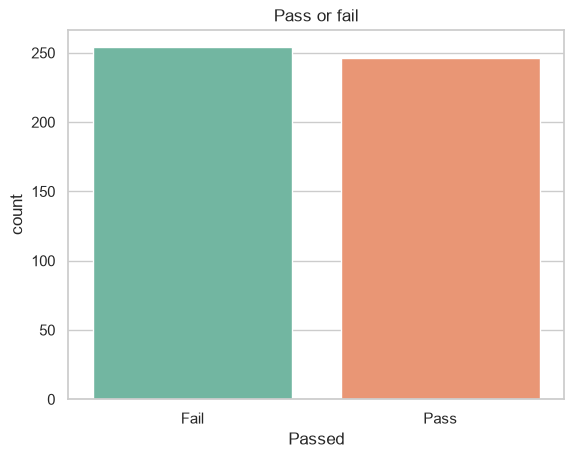

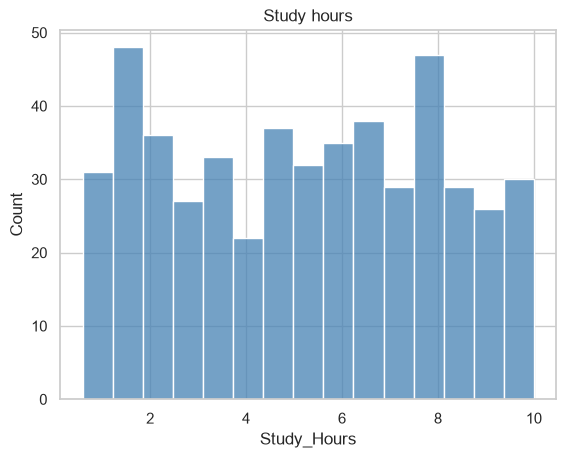

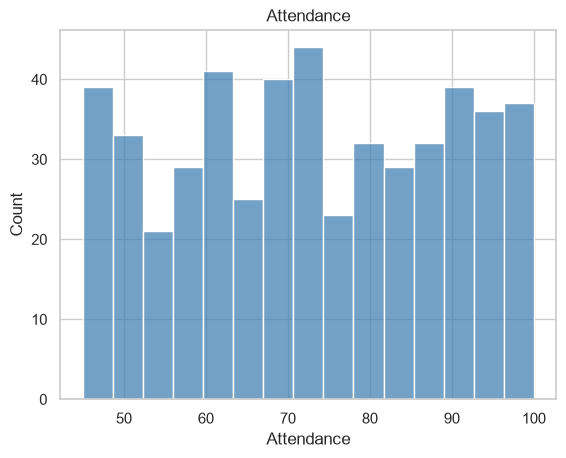

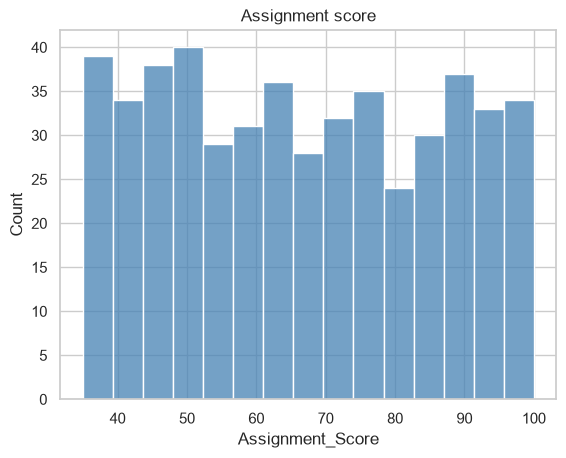

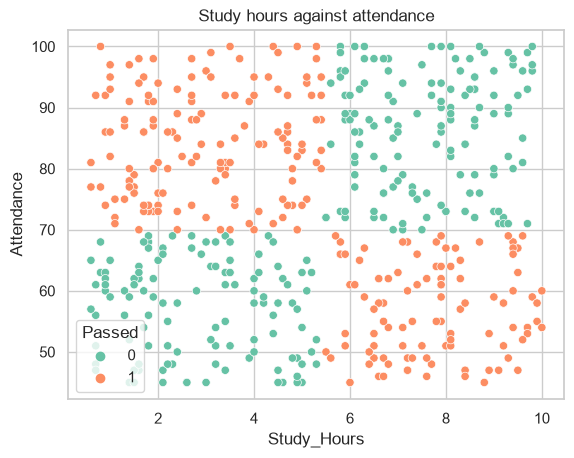

In [6]:
# One chart for the label, then one chart for each feature.
sns.countplot(data=students, x="Passed", palette="Set2")
plt.title("Pass or fail")
plt.xticks([0, 1], ["Fail", "Pass"])
plt.show()

sns.histplot(data=students, x="Study_Hours", bins=15, color="steelblue")
plt.title("Study hours")
plt.show()

sns.histplot(data=students, x="Attendance", bins=15, color="steelblue")
plt.title("Attendance")
plt.show()

sns.histplot(data=students, x="Assignment_Score", bins=15, color="steelblue")
plt.title("Assignment score")
plt.show()

# The two pass groups are the top-left and bottom-right of this plot.
# A straight line cannot put both groups on the pass side.
sns.scatterplot(data=students, x="Study_Hours", y="Attendance", hue="Passed", palette="Set2")
plt.title("Study hours against attendance")
plt.show()


,Study_Hours,Attendance,Assignment_Score
Passed,,,
0,5.46,73.03,65.61
1,4.95,72.88,67.46


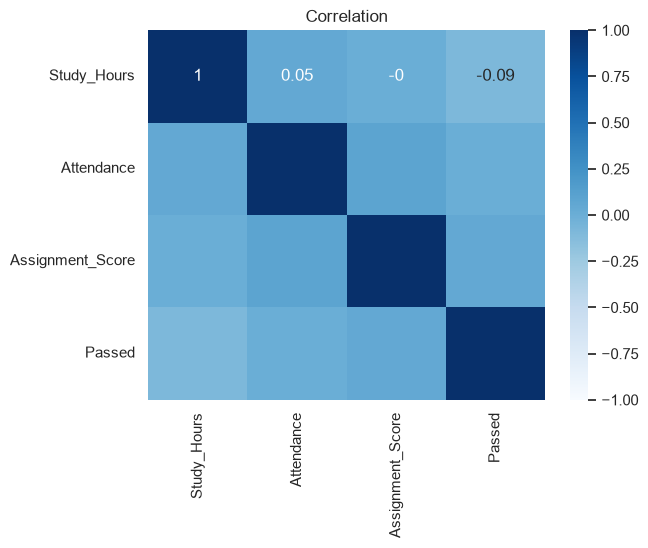

In [7]:
# The two pass corners pull the averages back toward the middle,
# so pass and fail look similar in a simple average.
display(students.groupby("Passed")[["Study_Hours", "Attendance", "Assignment_Score"]].mean().round(2))

# Correlation near 0 means a straight-line model gets little help from that column.
features = ["Study_Hours", "Attendance", "Assignment_Score", "Passed"]
sns.heatmap(students[features].corr().round(2), annot=True, cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlation")
plt.show()


## Prepare the training and test sets

`Student_ID` is not a feature. The other three columns are `X`. `Passed` is `y`.

Twenty percent of the rows are held out as the test set. `stratify=y` keeps a similar pass rate in both sets. The scaler is fit on the training rows only, then applied to both sets, so the test rows do not influence the scaling.

K-nearest neighbors and the support vector machine compare distances. Study hours run from about 1 to 10, while attendance runs from about 45 to 100. Without scaling, attendance would dominate the distance. Every model below is trained on the same scaled columns.


In [8]:
feature_columns = ["Study_Hours", "Attendance", "Assignment_Score"]
X = students[feature_columns]
y = students["Passed"]

# Same split for every model, so the confusion matrices can be compared.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train_scaled.shape[0])
print("Test rows:", X_test_scaled.shape[0])


Training rows: 400
Test rows: 100


## Evaluation: confusion matrix

Each model is scored with a confusion matrix on the test rows.

The rows of the matrix are the actual class. The columns are the predicted class. The order is Fail, then Pass.

|  | Predicted Fail | Predicted Pass |
| --- | --- | --- |
| Actual Fail | correct fail | fail predicted as pass |
| Actual Pass | pass predicted as fail | correct pass |

The two numbers on the diagonal are correct. The two numbers off the diagonal are mistakes. Fewer mistakes means a better matrix.


In [9]:
def show_confusion_matrix(y_true, y_pred, title):
    """Print the confusion matrix and draw it."""
    labels = [0, 1]
    matrix = confusion_matrix(y_true, y_pred, labels=labels)

    # Row 0 is actual Fail, row 1 is actual Pass.
    # Column 0 is predicted Fail, column 1 is predicted Pass.
    print(title)
    print(matrix)

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fail", "Pass"],
        yticklabels=["Fail", "Pass"],
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()
    return matrix


def mistake_count(matrix):
    """Off-diagonal cells: fail called pass, and pass called fail."""
    return int(matrix[0, 1] + matrix[1, 0])


## Logistic regression

Logistic regression draws one straight weighted line through the three features and turns that into a probability of passing. The predicted class is Pass when that probability is at least 0.5.

The two pass groups are in opposite corners, so one straight line cannot separate them. Expect mistakes in both off-diagonal cells.


Logistic regression
[[31 20]
 [24 25]]


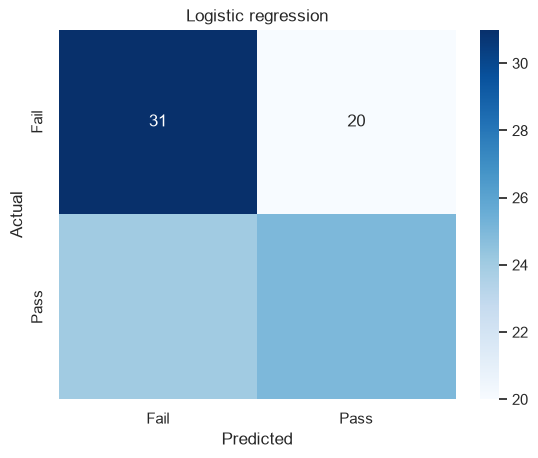

In [10]:
# max_iter is high enough for this small table to finish fitting.
logistic = LogisticRegression(max_iter=1000, random_state=42)
logistic.fit(X_train_scaled, y_train)

logistic_pred = logistic.predict(X_test_scaled)
logistic_matrix = show_confusion_matrix(y_test, logistic_pred, "Logistic regression")


## K-nearest neighbors

For a test student, k-nearest neighbors looks up the 5 closest students in the training set and predicts the class those neighbors share. If the neighbors are split, the majority class wins.

Nearby students fall in the same corner, so the neighbors usually share the right class. The matrix should show a heavier diagonal than logistic regression, and fewer mistakes off the diagonal.


K-nearest neighbors (k = 5)
[[47  4]
 [ 2 47]]


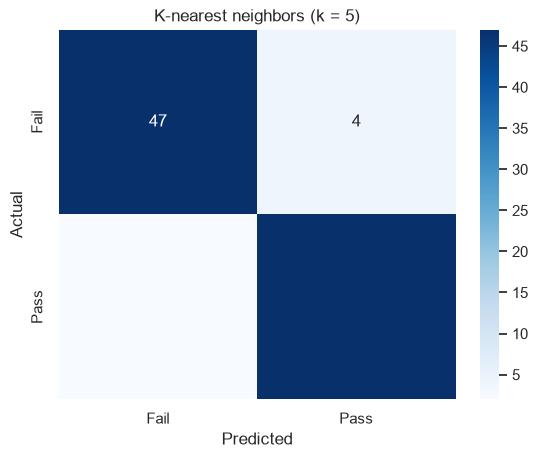

Logistic regression mistakes: 44
K-nearest neighbors mistakes: 6


In [11]:
# k = 5 is a common starting value: enough neighbors to smooth
# one odd student, still close to the point being classified.
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)
knn_matrix = show_confusion_matrix(y_test, knn_pred, "K-nearest neighbors (k = 5)")

# Compare the two matrices by counting the off-diagonal cells.
print("Logistic regression mistakes:", mistake_count(logistic_matrix))
print("K-nearest neighbors mistakes:", mistake_count(knn_matrix))


## Support vector machine

This support vector machine uses an RBF kernel. That kernel can bend around the two pass corners, instead of cutting the chart with one straight line. It is trained on the same scaled columns as the models above.


Support vector machine
[[45  6]
 [ 2 47]]


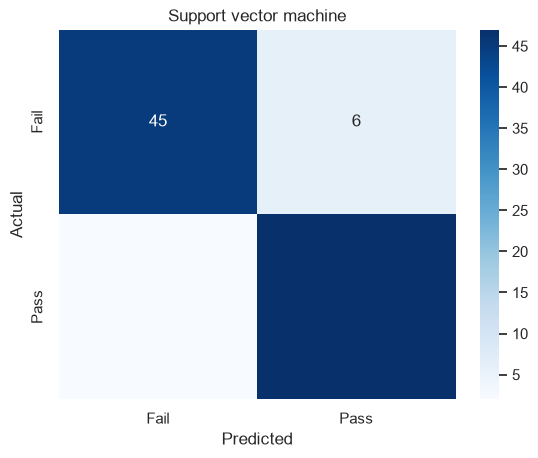

array([[45,  6],
       [ 2, 47]])

In [12]:
# kernel="rbf" is the curved boundary. A linear kernel would struggle here, like logistic regression.
svm = SVC(kernel="rbf", random_state=42)
svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)
show_confusion_matrix(y_test, svm_pred, "Support vector machine")


## Decision tree

A decision tree asks yes/no questions, such as "is attendance under 70?" and "are study hours under 5.5?". Each question splits the students. The class in a final group is the class of most training students who landed there.

Those questions can follow the two corners, so the tree does not need one straight line through all three features.


Decision tree
[[51  0]
 [ 1 48]]


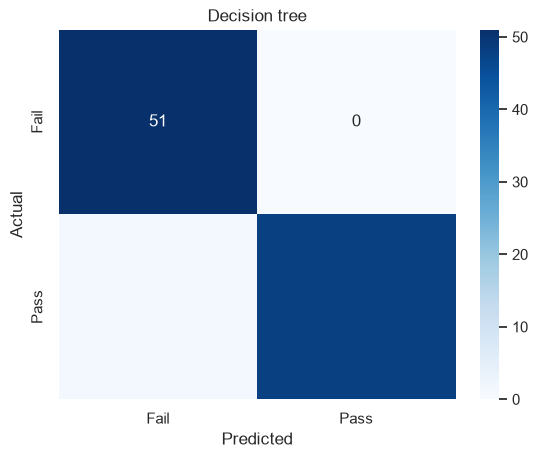

array([[51,  0],
       [ 1, 48]])

In [13]:
# random_state keeps the same tree if this cell is run again.
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train_scaled, y_train)

tree_pred = tree.predict(X_test_scaled)
show_confusion_matrix(y_test, tree_pred, "Decision tree")


## Random forest

A random forest builds many decision trees. Each tree sees a random sample of the training rows. For a test student, every tree votes, and the majority vote is the prediction.


Random forest
[[50  1]
 [ 0 49]]


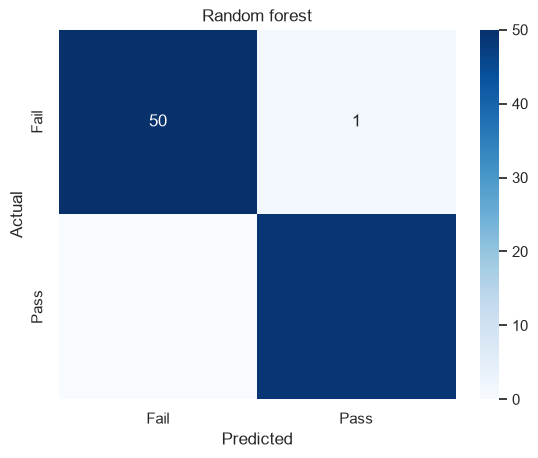

array([[50,  1],
       [ 0, 49]])

In [14]:
# 100 trees is enough for this small table. random_state keeps the votes repeatable.
forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train_scaled, y_train)

forest_pred = forest.predict(X_test_scaled)
show_confusion_matrix(y_test, forest_pred, "Random forest")
